# Chapitre 12 - Exercices 12.1 à 12.5

* 12.1 : équivalence entre la forme « perte charnière + pénalité » (12.25) et le problème
  quadratique (12.8) ;
* 12.2 : la forme à noyau (12.29) est (12.25) pour un noyau particulier ;
* 12.3 : régression à noyau quand on ne pénalise pas la constante ;
* 12.4 : distances dans l'espace des variables canoniques de la LDA ;
* 12.5 : classification de phonèmes par prototypes lisses (k-moyennes sur une base de
  splines).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (SVMClassifier, hinge_loss, rbf_kernel, polynomial_kernel,
                          poly2_features, LDA, kmeans, natural_spline_basis)
set_style()

## Exercice 12.1 : Équivalence de (12.25) et (12.8)

**Énoncé.** Montrer que les critères (12.25) et (12.8) sont équivalents, c'est-à-dire que

$$\text{(12.8)}\quad \min_{\beta,\beta_0,\xi}\ \tfrac12\|\beta\|^2 + C\sum_i\xi_i\ \ \text{s.c.}\ \ \xi_i\ge0,\ y_i(x_i^T\beta+\beta_0)\ge1-\xi_i$$

et

$$\text{(12.25)}\quad \min_{\beta,\beta_0}\ \sum_i\left[1 - y_i(x_i^T\beta + \beta_0)\right]_+ + \frac\lambda2\|\beta\|^2$$

ont les mêmes solutions $(\hat\beta,\hat\beta_0)$ lorsque $\lambda = 1/C$.

**Solution.** *Étape 1 : élimination des variables d'écart.* Fixons $(\beta,\beta_0)$ et
notons $m_i = y_i(x_i^T\beta + \beta_0)$. Les contraintes sur $\xi_i$ sont $\xi_i\ge0$ et
$\xi_i \ge 1 - m_i$, soit $\xi_i \ge \max(0, 1-m_i) = [1-m_i]_+$. Comme l'objectif est
strictement croissant en chaque $\xi_i$ (coefficient $C > 0$), le meilleur choix est la plus
petite valeur admissible : $\xi_i = [1 - m_i]_+$.

*Étape 2 : problème réduit.* Minimiser (12.8) revient donc à minimiser, en $(\beta,\beta_0)$
seulement,

$$\Phi(\beta,\beta_0) = \tfrac12\|\beta\|^2 + C\sum_i[1-m_i]_+ .$$

En effet, si $(\beta^\star,\beta_0^\star,\xi^\star)$ minimise (12.8), alors pour tout
$(\beta,\beta_0)$ : $\Phi(\beta^\star,\beta_0^\star)\le$ valeur de (12.8) en
$(\beta^\star,\beta_0^\star,\xi^\star)\le$ valeur de (12.8) en $(\beta,\beta_0,[1-m]_+) = \Phi(\beta,\beta_0)$.
Réciproquement, un minimiseur de $\Phi$ complété par $\xi_i = [1-m_i]_+$ minimise (12.8).

*Étape 3 : changement d'échelle.* Multiplier une fonction par la constante $\lambda = 1/C > 0$
ne change pas ses minimiseurs :

$$\lambda\,\Phi(\beta,\beta_0) = \sum_i[1 - y_i(x_i^T\beta+\beta_0)]_+ + \frac\lambda2\|\beta\|^2,$$

qui est exactement (12.25). Les deux problèmes ont donc les mêmes solutions, et la valeur
optimale de (12.25) vaut $\lambda$ fois celle de (12.8). $\square$

**Vérification numérique.** On résout (12.25) directement, avec un optimiseur générique
(`scipy.optimize.minimize`, méthode SLSQP) appliqué à la forme « épigraphe » sans le terme
quadratique en $\xi$, et on compare au SVM obtenu par le dual.

In [2]:
rng = np.random.RandomState(0)
X = np.vstack([rng.randn(25, 2) + [1, 1], rng.randn(25, 2) - [1, 1]])
y = np.r_[np.ones(25), -np.ones(25)]
C = 0.5
lam = 1 / C

def crit_1225(theta):
    beta, beta0 = theta[:2], theta[2]
    return hinge_loss(y * (X @ beta + beta0)).sum() + lam / 2 * beta @ beta

# (12.25) n'est pas dérivable : on passe par les écarts xi pour SLSQP
N = len(y)
obj = lambda v: v[3:].sum() + lam / 2 * v[:2] @ v[:2]
cons = [{"type": "ineq", "fun": lambda v: v[3:]},
        {"type": "ineq", "fun": lambda v: y * (X @ v[:2] + v[2]) - 1 + v[3:]}]
sol = minimize(obj, np.r_[0, 0, 0, np.ones(N)], constraints=cons, method="SLSQP",
               options={"maxiter": 500, "ftol": 1e-12})
svm = SVMClassifier(C=C, kernel="linear").fit(X, y)
print("solution directe (12.25)  : beta =", sol.x[:2].round(5), " beta0 = %.5f" % sol.x[2])
print("SVM via le dual (12.8)    : beta =", svm.coef_.round(5), " beta0 = %.5f" % svm.b_)
print("critère (12.25) : %.6f  ;  lambda x critère (12.8) : %.6f"
      % (crit_1225(np.r_[svm.coef_, svm.b_]), lam * svm.primal_objective()))

solution directe (12.25)  : beta = [0.78548 0.87657]  beta0 = -0.09282
SVM via le dual (12.8)    : beta = [0.78548 0.87657]  beta0 = -0.09282
critère (12.25) : 10.029449  ;  lambda x critère (12.8) : 10.029449


Le critère (12.25) est convexe et minimal en la solution du SVM : traçons-le le long de
quelques directions aléatoires issues de $(\hat\beta, \hat\beta_0)$.

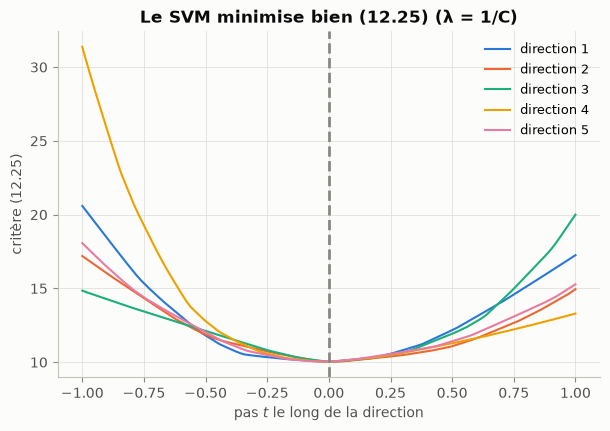

In [3]:
theta_hat = np.r_[svm.coef_, svm.b_]
tgrid = np.linspace(-1, 1, 201)
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in range(5):
    d = rng.randn(3); d /= np.linalg.norm(d)
    ax.plot(tgrid, [crit_1225(theta_hat + t * d) for t in tgrid], color=COLORS[k], lw=1.5,
            label="direction %d" % (k + 1))
ax.axvline(0, color=GRAY, ls="--")
ax.set_xlabel("pas $t$ le long de la direction"); ax.set_ylabel("critère (12.25)")
ax.set_title("Le SVM minimise bien (12.25) (λ = 1/C)")
ax.legend()
plt.show()

> **À retenir.** Les variables d'écart optimales sont $\xi_i = [1 - y_if(x_i)]_+$ : le SVM est
> un problème « perte charnière + pénalité ridge », avec $\lambda = 1/C$.

## Exercice 12.2 : La forme à noyau (12.29)

**Énoncé.** Montrer que la solution de

$$\text{(12.29)}\quad \min_{\beta_0,\alpha}\ \sum_i\left(1 - y_if(x_i)\right)_+ + \frac\lambda2\alpha^T\mathbf K\alpha,\qquad f(x) = \beta_0 + \sum_{i}\alpha_iK(x,x_i),$$

est la même que celle de (12.25) pour un noyau particulier.

**Rappels.** Dans (12.25), $f(x) = h(x)^T\beta + \beta_0$ avec un vecteur de fonctions de base
$h(x)\in\mathbb R^M$. Notons $H$ la matrice $N\times M$ de lignes $h(x_i)^T$. On choisit le
noyau **associé à $h$** : $K(x,x') = \langle h(x), h(x')\rangle$, de sorte que
$\mathbf K = HH^T$.

**Solution.** *Étape 1 : décomposition de $\beta$.* Tout $\beta\in\mathbb R^M$ s'écrit de
façon unique $\beta = H^T\alpha + \beta_\perp$, où $H^T\alpha$ est la projection orthogonale
de $\beta$ sur le sous-espace engendré par les $h(x_i)$ et $\beta_\perp$ lui est orthogonal,
c'est-à-dire $H\beta_\perp = 0$ ($h(x_i)^T\beta_\perp = 0$ pour tout $i$).

*Étape 2 : $\beta_\perp = 0$ à l'optimum.* Aux points d'apprentissage,
$f(x_i) = h(x_i)^T H^T\alpha + h(x_i)^T\beta_\perp + \beta_0 = (HH^T\alpha)_i + \beta_0$ : la
perte ne dépend pas de $\beta_\perp$. Par Pythagore,
$\|\beta\|^2 = \|H^T\alpha\|^2 + \|\beta_\perp\|^2$. Remplacer $\beta_\perp$ par 0 diminue donc
strictement le critère si $\beta_\perp\neq0$ : à l'optimum, $\beta = H^T\alpha$.

*Étape 3 : réécriture.* Avec $\beta = H^T\alpha = \sum_i\alpha_ih(x_i)$ :

* $f(x) = h(x)^T H^T\alpha + \beta_0 = \sum_i\alpha_i\langle h(x), h(x_i)\rangle + \beta_0 = \beta_0 + \sum_i\alpha_iK(x,x_i)$ ;
* $\|\beta\|^2 = \alpha^THH^T\alpha = \alpha^T\mathbf K\alpha$.

Le critère (12.25) devient exactement (12.29). $\square$

**Lien avec le dual.** Par (12.10), $\beta = \sum_i\hat\alpha_i^{\text{dual}}y_ih(x_i)$ avec
$C = 1/\lambda$ : on s'attend donc à $\alpha_i = \hat\alpha_i^{\text{dual}}y_i$.

**Vérification numérique** avec le noyau radial ($M = \infty$ : seule la forme (12.29) est
calculable). On résout (12.29) par SLSQP (variables $\beta_0$, $\alpha$, écarts $\xi$) et on
compare à notre SVM.

In [4]:
Xs, ys = X[::2], y[::2]          # 25 points pour garder un problème petit
Ks = rbf_kernel(Xs, Xs, 0.5)
n = len(ys)
lam2 = 1.0
obj2 = lambda v: v[1 + n:].sum() + lam2 / 2 * v[1:1 + n] @ Ks @ v[1:1 + n]
cons2 = [{"type": "ineq", "fun": lambda v: v[1 + n:]},
         {"type": "ineq", "fun": lambda v: ys * (v[0] + Ks @ v[1:1 + n]) - 1 + v[1 + n:]}]
sol2 = minimize(obj2, np.r_[0, np.zeros(n), np.ones(n)], constraints=cons2, method="SLSQP",
                options={"maxiter": 1000, "ftol": 1e-12})
svm2 = SVMClassifier(C=1 / lam2, kernel="rbf", gamma=0.5).fit(Xs, ys)
print("beta0 : (12.29) %.4f   SVM %.4f" % (sol2.x[0], svm2.b_))
print("écart max | alpha_(12.29) - alpha_dual * y | = %.2e" % np.abs(sol2.x[1:1 + n] - svm2.alpha_ * ys).max())
Zg = rng.randn(200, 2) * 1.5
f_1229 = sol2.x[0] + rbf_kernel(Zg, Xs, 0.5) @ sol2.x[1:1 + n]
print("écart max des fonctions f sur 200 points : %.2e" % np.abs(f_1229 - svm2.decision_function(Zg)).max())

beta0 : (12.29) 0.3350   SVM 0.3350
écart max | alpha_(12.29) - alpha_dual * y | = 8.49e-06
écart max des fonctions f sur 200 points : 5.56e-07


> **À retenir.** Pour $K(x,x') = \langle h(x),h(x')\rangle$, la solution de (12.25) vit dans
> l'espace engendré par les $h(x_i)$ ; (12.29) en est la paramétrisation par $\alpha$, avec la
> pénalité $\|\beta\|^2 = \alpha^T\mathbf K\alpha$.

## Exercice 12.3 : Ne pas pénaliser la constante

**Énoncé.** On modifie (12.43) en ne pénalisant pas la constante :

$$\min_{\beta_0,\beta}\ H(\beta,\beta_0) = \sum_{i=1}^NV(y_i - f(x_i)) + \frac\lambda2\sum_{m=1}^M\beta_m^2,\qquad f(x) = \beta_0 + \sum_m\beta_mh_m(x),$$

où $\beta_0$ est libre (non pénalisé). Formuler le problème et caractériser sa solution.

**Solution (perte $V$ dérivable et convexe).** Notons $r_i = y_i - f(x_i)$ les résidus.
Les conditions d'optimalité s'obtiennent en annulant les dérivées partielles :

* par rapport à $\beta_m$ : $-\sum_iV'(r_i)h_m(x_i) + \lambda\beta_m = 0$, d'où
  $\hat\beta = \frac1\lambda\sum_iV'(r_i)\,h(x_i)$ ;
* par rapport à $\beta_0$ : $-\sum_iV'(r_i) = 0$.

En posant $\hat a_i = V'(r_i)/\lambda$, on obtient la **représentation**

$$\hat f(x) = \hat\beta_0 + \sum_{i=1}^N\hat a_iK(x,x_i),\qquad K(x,x') = \sum_mh_m(x)h_m(x'),\qquad \sum_{i=1}^N\hat a_i = 0.$$

La seule différence avec (12.44) est la **contrainte $\sum_i\hat a_i = 0$** (et le terme
$\hat\beta_0$). C'est exactement la contrainte $\sum_i(\alpha_i^* - \alpha_i) = 0$ du SVM de
régression (12.41), où $V = V_\varepsilon$ et $\beta_0$ n'est pas pénalisé.

**Cas de la perte quadratique $V(r) = r^2$.** Alors $V'(r) = 2r$, donc $\hat a = 2r/\lambda$,
soit $r = \frac\lambda2\hat a$. Comme $r = y - \hat\beta_0\mathbf 1 - \mathbf K\hat a$, on
obtient le système linéaire « bordé » de taille $N+1$ :

$$\begin{pmatrix}\mathbf K + \frac\lambda2I & \mathbf 1\\ \mathbf 1^T & 0\end{pmatrix}\begin{pmatrix}\hat a\\ \hat\beta_0\end{pmatrix} = \begin{pmatrix}y\\0\end{pmatrix}.$$

Avec $M_\lambda = \mathbf K + \frac\lambda2 I$ (inversible car $\mathbf K$ est semi-définie
positive), la première ligne donne $\hat a = M_\lambda^{-1}(y - \hat\beta_0\mathbf 1)$ et la
contrainte $\mathbf 1^T\hat a = 0$ donne
$\hat\beta_0 = \dfrac{\mathbf 1^TM_\lambda^{-1}y}{\mathbf 1^TM_\lambda^{-1}\mathbf 1}$ : une
moyenne pondérée des $y_i$.

**Vérification.** Avec $h(x) = (\sqrt2x_j, x_j^2, \sqrt2x_jx_k)$ (le plongement du noyau
$(1+\langle x,x'\rangle)^2$ privé de sa constante), $K(x,x') = (1+\langle x,x'\rangle)^2 - 1$.
On compare la solution du système bordé à la solution directe dans l'espace des $h$.

In [5]:
rng = np.random.RandomState(1)
Xr = rng.randn(40, 2)
yr = 10 + Xr[:, 0] ** 2 - Xr[:, 1] + 0.3 * rng.randn(40)       # réponse décalée de +10
lam3 = 4.0
Hm = poly2_features(Xr)[:, 1:]                       # sans la colonne constante
Kr = Hm @ Hm.T
np.testing.assert_allclose(Kr, polynomial_kernel(Xr, Xr, 2) - 1, atol=1e-10)
# (i) noyau, système bordé
Mb = np.block([[Kr + lam3 / 2 * np.eye(40), np.ones((40, 1))], [np.ones((1, 40)), np.zeros((1, 1))]])
sol3 = np.linalg.solve(Mb, np.r_[yr, 0])
a_hat, b0_hat = sol3[:40], sol3[40]
# (ii) directement dans l'espace des h : moindres carrés + ridge sans pénaliser la constante
Ha = np.column_stack([np.ones(40), Hm])
P = np.eye(Ha.shape[1]); P[0, 0] = 0
coef = np.linalg.solve(Ha.T @ Ha + lam3 / 2 * P, Ha.T @ yr)
print("beta0 : noyau %.6f   direct %.6f" % (b0_hat, coef[0]))
print("somme des a_i = %.2e" % a_hat.sum())
print("écart max des ajustements : %.2e" % np.abs(b0_hat + Kr @ a_hat - Ha @ coef).max())

beta0 : noyau 10.070332   direct 10.070332
somme des a_i = 2.94e-15
écart max des ajustements : 1.07e-14


(La pénalité $\frac\lambda2\|\beta\|^2$ avec la perte $r^2$ correspond à un ridge de paramètre
$\lambda/2$ dans les équations normales.) Pourquoi ne pas pénaliser la constante ? Si on la
pénalise, l'ajustement est tiré vers 0 et la prédiction dépend de l'origine choisie pour $y$.

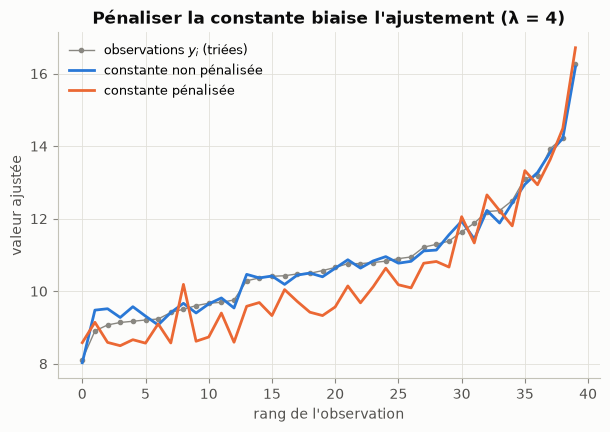

In [6]:
Kfull = polynomial_kernel(Xr, Xr, 2)                     # constante incluse dans h, donc pénalisée
a_pen = np.linalg.solve(Kfull + lam3 / 2 * np.eye(40), yr)
order = np.argsort(yr)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(yr[order], color=GRAY, marker="o", ms=3, lw=1, label="observations $y_i$ (triées)")
ax.plot((b0_hat + Kr @ a_hat)[order], color=BLUE, label="constante non pénalisée")
ax.plot((Kfull @ a_pen)[order], color=ORANGE, label="constante pénalisée")
ax.set_xlabel("rang de l'observation"); ax.set_ylabel("valeur ajustée")
ax.set_title("Pénaliser la constante biaise l'ajustement (λ = 4)")
ax.legend()
plt.show()

> **À retenir.** Ne pas pénaliser $\beta_0$ ajoute la contrainte $\sum_i\hat a_i = 0$ à la
> représentation $\hat f = \hat\beta_0 + \sum_i\hat a_iK(\cdot,x_i)$ ; c'est la structure
> du SVM de régression.

## Exercice 12.4 : Distances dans l'espace canonique de la LDA

**Énoncé.** On effectue une LDA de rang réduit pour $K$ groupes : on calcule les variables
canoniques $z = U^Tx$ de dimension $L\le K-1$, où $U$ est la matrice $p\times L$ des
coefficients discriminants ($p > K$).

(a) Si $L = K-1$, montrer que
$\|z-\bar z_k\|^2 - \|z - \bar z_{k'}\|^2 = \|x-\bar x_k\|_W^2 - \|x-\bar x_{k'}\|_W^2$, où
$\|\cdot\|_W$ est la distance de Mahalanobis associée à la covariance intra-classe $W$.

(b) Si $L < K-1$, montrer que le membre de gauche mesure la différence des distances de
Mahalanobis au carré pour les lois **projetées** sur le sous-espace engendré par $U$.

**Rappels.** $\|v\|_W^2 = v^TW^{-1}v$. Les coefficients discriminants sont les vecteurs propres
généralisés $Bu = \mu Wu$ ($B$ : covariance inter-classes), normalisés par $U^TWU = I_L$. On
« blanchit » les données : $x^* = W^{-1/2}x$, de sorte que $\|x - \bar x_k\|_W^2 = \|x^* - \bar x_k^*\|^2$
(norme euclidienne). En posant $V = W^{1/2}U$, on a $V^TV = U^TWU = I_L$ (colonnes
orthonormées), $z = U^Tx = V^Tx^*$, et les colonnes de $V$ sont les vecteurs propres de
$B^* = W^{-1/2}BW^{-1/2}$, matrice de covariance des centroïdes blanchis $\bar x^*_k$.

**Solution (a).** Les $K$ centroïdes blanchis $\bar x^*_k$ engendrent un sous-espace affine de
dimension au plus $K-1$ passant par leur moyenne $\bar x^*$ : les vecteurs $\bar x^*_k - \bar x^*$
sont dans l'image de $B^*$, engendrée (génériquement) par ses $K-1$ vecteurs propres de valeur
propre non nulle, c'est-à-dire par les colonnes de $V$ quand $L = K-1$. Soit $P = VV^T$ le
projecteur orthogonal sur ce sous-espace. Par Pythagore :

$$\|x^*-\bar x^*_k\|^2 = \|P(x^* - \bar x^*_k)\|^2 + \|(I-P)(x^*-\bar x^*_k)\|^2.$$

* Second terme : comme $\bar x_k^* - \bar x^*\in\mathrm{Im}\,P$, on a
  $(I-P)\bar x_k^* = (I-P)\bar x^*$, donc ce terme vaut $\|(I-P)(x^* - \bar x^*)\|^2$ et
  **ne dépend pas de $k$**.
* Premier terme : $\|P v\|^2 = v^TVV^TVV^Tv = \|V^Tv\|^2$ (car $V^TV = I$), donc
  $\|P(x^*-\bar x^*_k)\|^2 = \|V^Tx^* - V^T\bar x^*_k\|^2 = \|z - \bar z_k\|^2$.

En faisant la différence pour $k$ et $k'$, le terme indépendant de $k$ disparaît, d'où
l'identité (a). $\square$

**Solution (b).** Pour $L<K-1$, on a toujours $\|z-\bar z_k\|^2 = \|P_L(x^*-\bar x_k^*)\|^2$
avec $P_L = V_LV_L^T$, mais les centroïdes ne sont plus dans l'image de $P_L$ : l'identité
exacte disparaît. Interprétation : si $X\mid G=k\sim N(\mu_k, W)$, la variable projetée
$Z = U^TX$ suit $N(U^T\mu_k, U^TWU) = N(U^T\mu_k, I_L)$. La distance de Mahalanobis au carré de
$z$ à la classe $k$ **pour la loi projetée** est donc
$(z - U^T\mu_k)^T(U^TWU)^{-1}(z - U^T\mu_k) = \|z - \bar z_k\|^2$. Le membre de gauche est
donc la différence des distances de Mahalanobis pour les lois projetées sur le sous-espace
engendré par $U$. $\square$

**Vérification** sur les voyelles (K = 11 classes, p = 10 - on prend 4 classes pour avoir
$p > K$) : (a) avec $L = K-1 = 3$ ; (b) avec $L = 2$ et la covariance projetée $U^TWU$.

In [7]:
Xv, gv = datasets.load_vowel("train")
keep = np.isin(gv, [1, 2, 3, 4])
Xv, gv = Xv[keep], gv[keep]
lda4 = LDA().fit(Xv, gv)
U, mu_eig = lda4.canonical_directions()
Wi = np.linalg.inv(lda4.W_)
x0 = Xv[:6]
maha = np.column_stack([np.einsum("ij,jk,ik->i", x0 - m, Wi, x0 - m) for m in lda4.means_])
for L in [3, 2]:
    UL = U[:, :L]
    z, zbar = x0 @ UL, lda4.means_ @ UL
    dz = ((z[:, None, :] - zbar[None]) ** 2).sum(-1)
    print("L = %d : U^T W U = I ? %s" % (L, np.allclose(UL.T @ lda4.W_ @ UL, np.eye(L))))
    print("   différences (classe k - classe 1), espace z :", (dz[0, 1:] - dz[0, 0]).round(4))
    print("   différences (classe k - classe 1), Mahalanobis :", (maha[0, 1:] - maha[0, 0]).round(4))

L = 3 : U^T W U = I ? True
   différences (classe k - classe 1), espace z : [ 9.5956 15.4746 31.9383]
   différences (classe k - classe 1), Mahalanobis : [ 9.5956 15.4746 31.9383]
L = 2 : U^T W U = I ? True
   différences (classe k - classe 1), espace z : [ 8.1942 16.0097 31.4166]
   différences (classe k - classe 1), Mahalanobis : [ 9.5956 15.4746 31.9383]


Pour $L = 3$ les deux lignes coïncident ; pour $L = 2$ elles diffèrent (l'information de la
troisième direction est perdue), et la valeur obtenue est bien la distance de Mahalanobis
des lois projetées, de covariance $U_L^TWU_L = I_L$.

> **À retenir.** Classer au centroïde le plus proche dans l'espace canonique complet
> ($L = K-1$, distance euclidienne) équivaut à la règle de Mahalanobis de la LDA ; en rang
> réduit, c'est la même règle appliquée aux données projetées.

## Exercice 12.5 : Prototypes lisses pour les phonèmes

**Énoncé (reformulé).** Les données *phoneme* contiennent des log-périodogrammes (256
fréquences) de cinq phonèmes prononcés par de nombreux locuteurs.

(a) Tracer, pour chaque classe, les courbes en fonction de la fréquence.

(b) On veut classer par **prototype le plus proche** : $k$-moyennes dans chaque classe, puis
affectation à la classe du centre le plus proche. Les données étant de grande dimension, on
impose aux prototypes d'être **lisses** : $m = \mathbf B\theta$ où $\mathbf B$ ($256\times J$)
est une base de splines cubiques naturelles avec des nœuds uniformes sur $(0, 255)$. Décrire
la procédure, en évitant les calculs coûteux en grande dimension (indication : prendre
$\mathbf B$ orthogonale).

(c) La mettre en œuvre : apprentissage/test 50/50 **sans séparer les locuteurs**, $K = 1, 3,
5, 7$ centres par classe et $J = 5, 10, 15$ nœuds, avec les mêmes valeurs initiales des
$k$-moyennes pour chaque $J$ ; comparer.

In [8]:
ph = datasets.load_phoneme()
Xp = ph[["x.%d" % j for j in range(1, 257)]].to_numpy(float)
gp = ph["g"].to_numpy()
spk = ph["speaker"].str.split(".").str[2].to_numpy()
classes = np.array(["aa", "ao", "dcl", "iy", "sh"])
print(Xp.shape, "observations ;", len(np.unique(spk)), "locuteurs")

(4509, 256) observations ; 437 locuteurs


### (a) Les courbes par classe

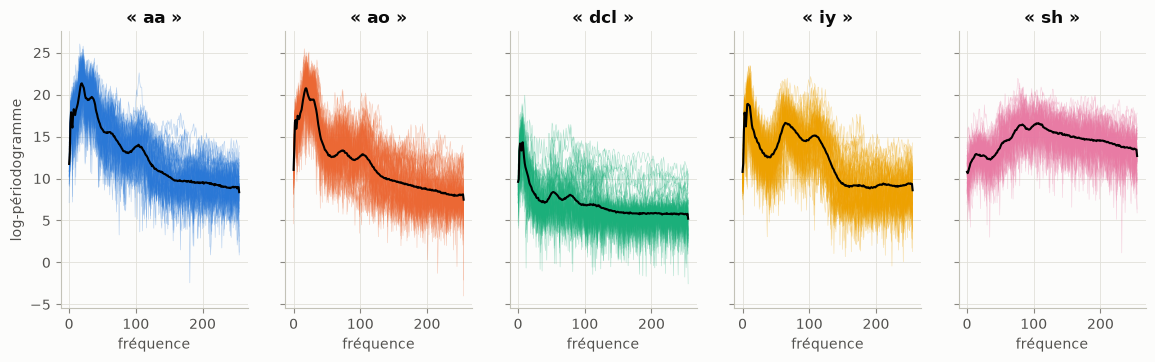

In [9]:
freq = np.arange(256)
fig, axes = plt.subplots(1, 5, figsize=(14, 3.6), sharey=True)
rng = np.random.RandomState(0)
for k, (ax, c) in enumerate(zip(axes, classes)):
    idx = rng.choice(np.flatnonzero(gp == c), 60, replace=False)
    ax.plot(freq, Xp[idx].T, color=COLORS[k], lw=0.4, alpha=0.35)
    ax.plot(freq, Xp[gp == c].mean(0), color="k", lw=1.5)
    ax.set_title("« %s »" % c)
    ax.set_xlabel("fréquence")
axes[0].set_ylabel("log-périodogramme")
plt.show()

(60 courbes tirées au hasard par classe ; en noir la moyenne.) Les courbes sont très bruitées
mais les moyennes sont lisses : il est naturel de chercher des prototypes lisses. « aa » et
« ao » se ressemblent beaucoup.

### (b) La procédure

Soit $\mathbf B$ une base **orthonormée** ($\mathbf B^T\mathbf B = I_J$) de l'espace des splines
(on orthonormalise la base de splines naturelles par une décomposition QR, ce qui ne change
pas l'espace engendré). $P = \mathbf B\mathbf B^T$ est alors le projecteur orthogonal sur cet
espace. Pour une courbe $x\in\mathbb R^{256}$ et un prototype $m = \mathbf B\theta$, par
Pythagore ($x - Px \perp$ espace des splines, et $Px - \mathbf B\theta$ dans cet espace) :

$$\|x - \mathbf B\theta\|^2 = \|x - Px\|^2 + \|Px - \mathbf B\theta\|^2 = \|x - Px\|^2 + \|\mathbf B^Tx - \theta\|^2,$$

où l'on a utilisé $\|\mathbf B v\| = \|v\|$ (colonnes orthonormées).

Conséquences :

* le premier terme ne dépend pas du prototype. Le critère des $k$-moyennes
  $\sum_i\|x_i - \mathbf B\theta_{c(i)}\|^2$ vaut donc une constante plus
  $\sum_i\|\tilde x_i - \theta_{c(i)}\|^2$, avec les **coordonnées réduites**
  $\tilde x_i = \mathbf B^Tx_i\in\mathbb R^J$ ;
* il suffit de faire les $k$-moyennes **ordinaires en dimension $J$** sur les $\tilde x_i$ : les
  centres $\hat\theta$ donnent les prototypes $\mathbf B\hat\theta$ ;
* de même, la règle « prototype le plus proche » se calcule sur les $\tilde x$.

Le seul calcul en dimension 256 est le produit $\mathbf B^Tx_i$, fait une fois pour toutes.

### (c) Mise en œuvre

**Découpage par locuteurs.** Les courbes d'un même locuteur sont corrélées (même voix). Si
un locuteur apparaissait à la fois en apprentissage et en test, l'erreur test serait trop
optimiste : on évaluerait la capacité à reconnaître des voix déjà entendues, pas à
généraliser à de nouveaux locuteurs. On tire donc au hasard la moitié des **locuteurs**.

In [10]:
rng = np.random.RandomState(0)
speakers = np.unique(spk)
train_spk = rng.choice(speakers, len(speakers) // 2, replace=False)
tr = np.isin(spk, train_spk)
print("apprentissage : %d courbes, test : %d courbes" % (tr.sum(), (~tr).sum()))

def spline_basis(J):
    """Base orthonormée (256 x (J+2)) de splines naturelles : J nœuds intérieurs + 2 frontières."""
    knots = np.linspace(0, 255, J + 2)
    Bn = natural_spline_basis(freq.astype(float), knots)
    Qb, _ = np.linalg.qr(Bn)
    return Qb

B10 = spline_basis(10)
print("B^T B = I ?", np.allclose(B10.T @ B10, np.eye(B10.shape[1])))

apprentissage : 2258 courbes, test : 2251 courbes
B^T B = I ? True


Les centres initiaux des $k$-moyennes sont des observations tirées une fois pour toutes dans
chaque classe (mêmes indices pour toutes les valeurs de $J$, comme demandé).

In [11]:
Ks_list, Js = [1, 3, 5, 7], [5, 10, 15]
rng = np.random.RandomState(1)
# indices relatifs aux observations d'apprentissage de la classe c
init = {(c, K): rng.choice(np.sum(gp[tr] == c), K, replace=False) for c in classes for K in Ks_list}

def prototype_error(Xtr, gtr, Xte, gte, K):
    """k-moyennes dans chaque classe puis classement au prototype le plus proche."""
    centers, labels = [], []
    for c in classes:
        Xc = Xtr[gtr == c]
        cen, _ = kmeans(Xc, K, init=init[(c, K)])
        centers.append(cen); labels += [c] * K
    centers, labels = np.vstack(centers), np.array(labels)
    d2 = ((Xte[:, None, :] - centers[None]) ** 2).sum(-1)
    return np.mean(labels[d2.argmin(1)] != gte)

errs = np.zeros((len(Js) + 1, len(Ks_list)))
for a, J in enumerate(Js):
    Bj = spline_basis(J)
    Xt_red, Xe_red = Xp[tr] @ Bj, Xp[~tr] @ Bj           # coordonnées réduites
    for b, K in enumerate(Ks_list):
        errs[a, b] = prototype_error(Xt_red, gp[tr], Xe_red, gp[~tr], K)
for b, K in enumerate(Ks_list):                           # référence : sans lissage (dim. 256)
    errs[-1, b] = prototype_error(Xp[tr], gp[tr], Xp[~tr], gp[~tr], K)

import pandas as pd
pd.DataFrame(errs.round(3), index=["J = %d" % J for J in Js] + ["brut (256)"],
             columns=["K = %d" % K for K in Ks_list])

,K = 1,K = 3,K = 5,K = 7
J = 5,0.172,0.134,0.131,0.129
J = 10,0.138,0.110,0.110,0.105
J = 15,0.137,0.107,0.112,0.106
brut (256),0.134,0.104,0.113,0.106


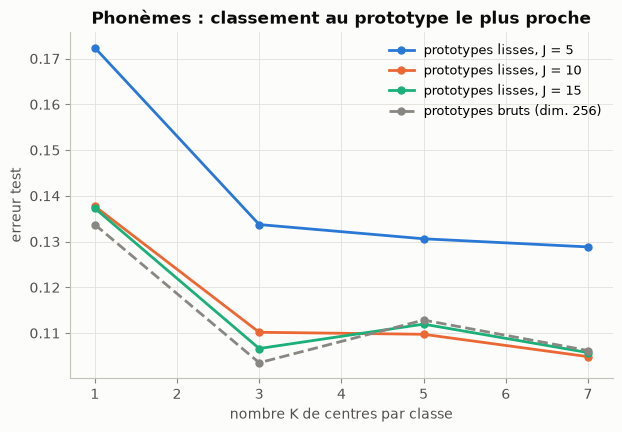

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for a, J in enumerate(Js):
    ax.plot(Ks_list, errs[a], marker="o", color=COLORS[a], label="prototypes lisses, J = %d" % J)
ax.plot(Ks_list, errs[-1], marker="o", color=GRAY, ls="--", label="prototypes bruts (dim. 256)")
ax.set_xlabel("nombre K de centres par classe"); ax.set_ylabel("erreur test")
ax.set_title("Phonèmes : classement au prototype le plus proche")
ax.legend()
plt.show()

Prototypes lisses obtenus pour $J = 10$, $K = 3$ (un panneau par classe) :

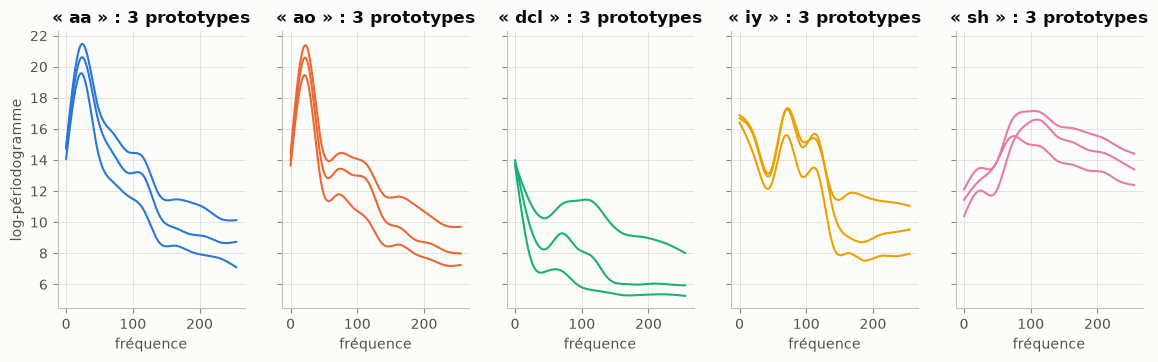

In [13]:
Bj = spline_basis(10)
fig, axes = plt.subplots(1, 5, figsize=(14, 3.6), sharey=True)
for k, (ax, c) in enumerate(zip(axes, classes)):
    cen, _ = kmeans(Xp[tr][gp[tr] == c] @ Bj, 3, init=init[(c, 3)])
    ax.plot(freq, (Bj @ cen.T), color=COLORS[k], lw=1.5)
    ax.set_title("« %s » : 3 prototypes" % c); ax.set_xlabel("fréquence")
axes[0].set_ylabel("log-périodogramme")
plt.show()

Avec $J = 5$ nœuds, les prototypes sont trop rigides ; dès $J = 10$, les prototypes lisses
font aussi bien que les prototypes bruts, pour un coût de calcul bien moindre (dimension
$J+2$ au lieu de 256). Passer de 1 à 3 centres par classe aide nettement, au-delà le gain est
faible ; la confusion « aa »/« ao » reste la principale source d'erreur.

> **À retenir.** Avec une base orthonormée, contraindre les prototypes à un sous-espace
> revient à projeter les données ($\tilde x = \mathbf B^Tx$) puis à travailler en petite
> dimension : Pythagore sépare un terme constant et un terme en dimension réduite.